GSEA, by cell type & stage for specific pathways

# Header

In [9]:
from utils import *

In [2]:
import sys
sys.path.insert(0, '/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src')
import cna

In [3]:
import gseapy as gp
import scanpy as sc
from itertools import product
from matplotlib.patches import Patch
from textwrap import fill

In [4]:
os.chdir('../')

In [5]:
import scanpy as sc
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [6]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from scipy import sparse
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def fast_spearman_ann(adata, obs_key, genes=None, chunk_size=2000, eps=1e-12):
    """
    Fast Spearman correlation between a per-cell variable (obs_key)
    and expression of each gene in adata.
    Returns a DataFrame with columns: rho, pval, fdr.
    """
    if genes is None:
        genes = adata.var_names
    X = adata[:, genes].X
    n_cells, n_genes = X.shape

    # rank-transform the covariate
    c = pd.to_numeric(adata.obs[obs_key], errors='coerce').to_numpy()
    r_c = rankdata(c, method='average')
    r_c0 = r_c - r_c.mean()
    norm_rc0 = np.linalg.norm(r_c0) + eps

    rho = np.empty(n_genes, dtype=float)

    for start in range(0, n_genes, chunk_size):
        end = min(start + chunk_size, n_genes)
        Xi = X[:, start:end]

        if sparse.issparse(Xi):
            Xi = Xi.toarray()

        # rank each gene (column) across cells
        R = np.apply_along_axis(rankdata, 0, Xi, method='average')
        R0 = R - R.mean(axis=0, keepdims=True)
        denomX = np.linalg.norm(R0, axis=0) + eps

        # Pearson on ranks = Spearman
        rho[start:end] = (R0.T @ r_c0) / (norm_rc0 * denomX)

    # --- p-values (two-sided) via t-approximation ---
    df = n_cells - 2
    # Clamp |rho| to < 1 to avoid division by zero
    rho_clamped = np.clip(rho, -1 + 1e-15, 1 - 1e-15)
    t_stat = rho_clamped * np.sqrt(df / (1 - rho_clamped**2))
    pval = 2 * student_t.sf(np.abs(t_stat), df=df)

    # --- FDR (Benjamini–Hochberg) ---
    fdr = multipletests(pval, method='fdr_bh')[1]

    out = pd.DataFrame(
        {'rho': rho, 'pval': pval, 'fdr': fdr},
        index=pd.Index(genes, name='gene')
    )
    out.name = f'spearman_{obs_key}'
    return out

In [8]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

# Load

In [17]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,N,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,N,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,N,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [18]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,predicted.celltype.l3,mapping.score,RNA_snn_res.0.8,seurat_clusters,dataset_name,RNA_snn_res.0.1,S.Score,G2M.Score,Phase,celltype_level3
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,CD4 TCM_1,0.827455,0,0,Pool137_10,0,-0.035611,-0.030749,G1,Naive CD4T
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,CD16 Mono,0.740965,5,5,Pool137_10,5,0.004613,0.004461,S,Nonclassical Monocyte
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,CD8 Naive,0.874696,6,6,Pool137_10,6,0.027257,-0.066766,S,Naive CD8T
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,CD4 TCM_1,0.842401,0,0,Pool137_10,0,-0.049705,0.004598,G2M,Naive CD4T
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,CD16 Mono,0.836383,5,5,Pool137_10,5,0.003770,-0.014496,S,Nonclassical Monocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,CD14 Mono,0.925401,2,1,Pool138_9,1,0.128049,0.014490,S,Classical Monocyte
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,CD4 TCM_3,0.890462,5,0,Pool138_9,0,0.020027,-0.014519,S,Effector Memory CD4T
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,CD4 TCM_1,0.842334,1,0,Pool138_9,0,-0.052514,-0.009035,G1,Naive CD4T
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,CD4 TCM_1,0.824522,1,0,Pool138_9,0,-0.042068,0.002366,G2M,Naive CD4T


In [19]:
for col in ['age', 'race-stage', 'race', 'group', 'diabetes', 'obesity']:
    dat.obs[col] = dat.obs['dataset_name'].map(meta.set_index('dataset_name')[col])
    
for xcol in ['diabetes','obesity']:
    dat.obs[xcol] = [1 if x=='Y' else 0 for x in dat.obs[xcol]]

xcol = 'group'
dat.obs[xcol] = [0 if x=='HRL' else 1 if x=='DCIS' else 2 for x in dat.obs[xcol]]

xcol = 'race'
dat.obs[xcol] = [0 if x=='NHW' else 1 if x=='NHB' else None for x in dat.obs[xcol]]

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race',
       'group', 'diabetes', 'obesity'],
      dtype='object')

In [20]:
celltype_major = 'DC'

In [21]:
d = dat[
    dat.obs['predicted.celltype.l1'] == celltype_major
]
d

View of AnnData object with n_obs × n_vars = 7936 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standar

In [22]:
umap = pd.read_csv(f"data/03_cleandata/ft_{celltype_major}_UmapCoords.csv",
                   index_col=2
                  ).loc[d.obs.index,:]

d.obsm['X_umap'] = umap.values

/tmp/ipykernel_2591247/3805644948.py:5: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  d.obsm['X_umap'] = umap.values


# Calc

In [23]:
len(d.obs['dataset_name'].unique())

55

## Overall

In [24]:
d_sub = d

sc.pp.neighbors(d_sub)

covars = ['race', 'age']
for v in ['obesity', 'diabetes']:
    if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
        covars.append(v)
        
samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                               covars,     # the metadata columns to use
                               'dataset_name')                        # the column of d.obs that contains sample IDs

samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]


res = cna.tl.association(
    d_sub,
    samplem.race, 
    'dataset_name',
    covs=samplem[[c for c in covars if c != 'race']],
    batches=samplem.batch,
    key_added='race_coef',
    return_full=True
)

/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:87: UserWarning: global association p-value attained minimal possible value. Consider increasing Nnull
  warnings.warn('global associati

In [25]:
pkl.dump(d_sub, 
         open('data/10_cna/DC_cna.pkl', 'wb'))

In [26]:
pkl.dump(res, 
         open('data/10_cna/fullres_DC.pkl', 'wb'))

## Cell type + Disease state

In [27]:
# change back
xcol = 'group'
d.obs['disease_state'] = ['HRL' if x==0 else 'DCIS' if x==1 else 'BC' for x in d.obs[xcol]]

In [28]:
import scanpy as sc

for celltype in [
    'cDC1',
    'cDC2',
    'pDC'
]:
    for group in ['HRL','DCIS','BC']:
        
        d_sub = d[
        (d.obs['celltype_level3']==celltype) &
        (d.obs['disease_state']==group)
        ]
    
        sc.pp.neighbors(d_sub)

        covars = ['race', 'age']
        for v in ['obesity', 'diabetes']:
            if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
                covars.append(v)
                
        samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                       covars,     # the metadata columns to use
                                       'dataset_name')                        # the column of d.obs that contains sample IDs
        
        samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
        
        
        res = cna.tl.association(
            d_sub,
            samplem.race, 
            'dataset_name',
            covs=samplem[[c for c in covars if c != 'race']],
            batches=samplem.batch,
            key_added='race_coef',
            return_full=True,
            allow_low_sample_size=True
        )
    
        res = fast_spearman_ann(d_sub, 
                            obs_key='race_coef', 
                            genes=d_sub.var_names, chunk_size=2000)
    
        gene_corr_df = pd.DataFrame(res)
        
        pre_res1 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                             gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                             threads=1,
                             min_size=5,
                             max_size=1000,
                             permutation_num=1000, # reduce number to speed up testing
                             outdir=None, # don't write to disk
                             seed=1024,
                             verbose=True, # see what's going on behind the scenes
                            ).res2d
    
        pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                             gene_sets='data/11_genesets/immport_allgenelist.gmt',
                             threads=1,
                             min_size=5,
                             max_size=1000,
                             permutation_num=1000, # reduce number to speed up testing
                             outdir=None, # don't write to disk
                             seed=1024,
                             verbose=True, # see what's going on behind the scenes
                            ).res2d
    
        pre_res1.to_csv(f'data/Figure6/CNArankNHBvsW_{celltype}_{group}_hallmark.csv')
        pre_res2.to_csv(f'data/Figure6/CNArankNHBvsW_{celltype}_{group}_immport.csv')
        print(f'Done for {celltype}_{group}')
    


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 3 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for cDC1_HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for cDC1_DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for cDC1_BC


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for cDC2_HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 1 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for cDC2_DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for cDC2_BC


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2026-01-05 13:51:00,797 [WARNING] Duplicated values found in preranked stats: 36.55% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-01-05 13:51:00,799 [INFO] Parsing data files for GSEA.............................
2026-01-05 13:51:00,845 [INFO] 0000 gene_sets have been fi

Done for pDC_HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2026-01-05 13:51:24,511 [WARNING] Duplicated values found in preranked stats: 49.70% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-01-05 13:51:24,512 [INFO] Parsing data files for GSEA.............................
2026-01-05 13:51:24,561 [INFO] 0000 gene_sets have been fi

Done for pDC_DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2026-01-05 13:51:50,125 [WARNING] Duplicated values found in preranked stats: 38.24% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-01-05 13:51:50,126 [INFO] Parsing data files for GSEA.............................
2026-01-05 13:51:50,174 [INFO] 0000 gene_sets have been fi

Done for pDC_BC


## Disease state

In [29]:
for group in ['HRL','DCIS','BC']:
    
    d_sub = d[
    (d.obs['disease_state']==group)
    ]

    sc.pp.neighbors(d_sub)

    covars = ['race', 'age']
    for v in ['obesity', 'diabetes']:
        if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
            covars.append(v)
            
    samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                   covars,     # the metadata columns to use
                                   'dataset_name')                        # the column of d.obs that contains sample IDs
    
    samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
    
    
    res = cna.tl.association(
        d_sub,
        samplem.race, 
        'dataset_name',
        covs=samplem[[c for c in covars if c != 'race']],
        batches=samplem.batch,
        key_added='race_coef',
        return_full=True
    )

    res = fast_spearman_ann(d_sub, 
                        obs_key='race_coef', 
                        genes=d_sub.var_names, chunk_size=2000)

    gene_corr_df = pd.DataFrame(res)
    
    pre_res1 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    pre_res2 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/immport_allgenelist.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d

    pre_res1.to_csv(f'data/Figure6/CNArankNHBvsW_DC_{group}_hallmark.csv')
    pre_res2.to_csv(f'data/Figure6/CNArankNHBvsW_DC_{group}_immport.csv')
    print(f'Done for {group}')



/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 2 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.ob

Done for DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:229: UserWarning: Key 'race_coef' already exists in data.obs. Overwriting.
  warnings.warn(f"Key '{key_added}' already exists in data.obs. Overwriting.")
2026-01-05 13:53:18,972 [WARNING] Duplicated values found in preranked stats: 23.99% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-01-05 13:53:18,974 [INFO] Parsing data files for GSEA.............................
2026-01-05 13:53:19,012 [INFO] 0000 gene_sets have been fi

Done for BC


# Analysis

## Overall

In [9]:
with open('data/10_cna/overall_DC.pkl','rb') as f:
    d = pkl.load(f)

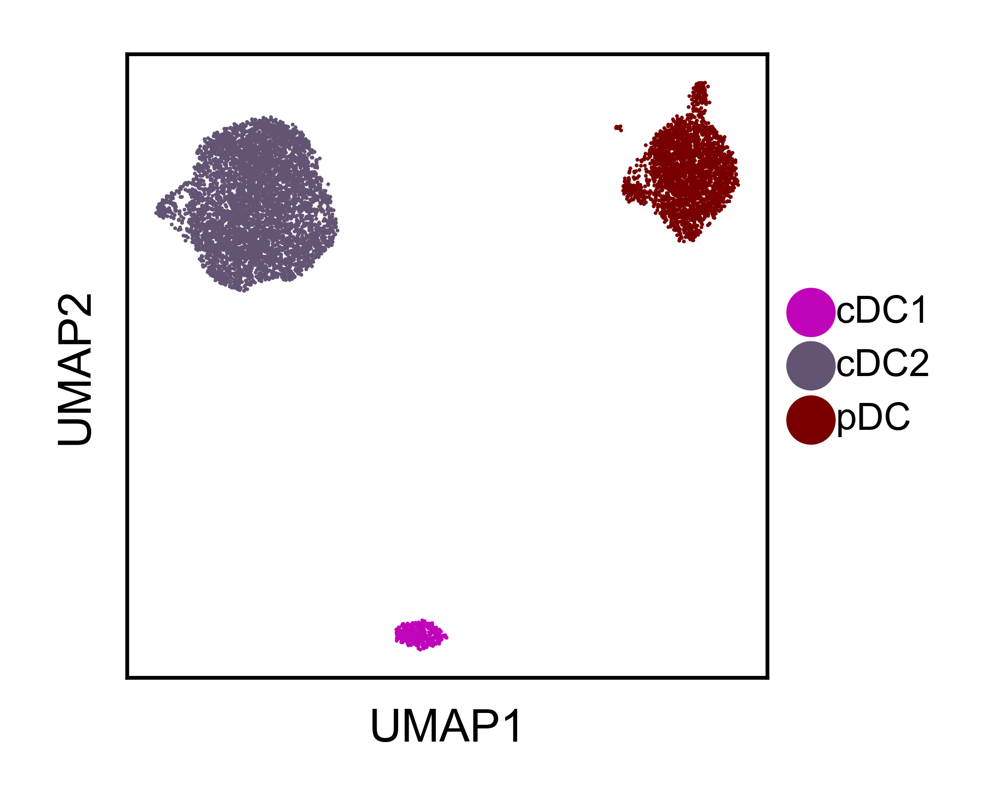

In [162]:
import scanpy as sc
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'celltype_level3'
# cell_colors = {x: palsamplem['race-stage'] = samplem.apply(lambda row: f"{row['race']}-{row['group']}", axis=1)
# Counter(samplem['race-stage'])
#palette[ct] = (0.8, 0.8, 0.8)

order = cells_group['DC']
pal_ordered = [palette_all[c] for c in order]


d.obs['celltype_level3_new'] = d.obs['celltype_level3'] 

sc.pl.umap(
    d,
    color='celltype_level3_new',
    palette=pal_ordered,
    size=1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6_2/DC_celltype.svg')

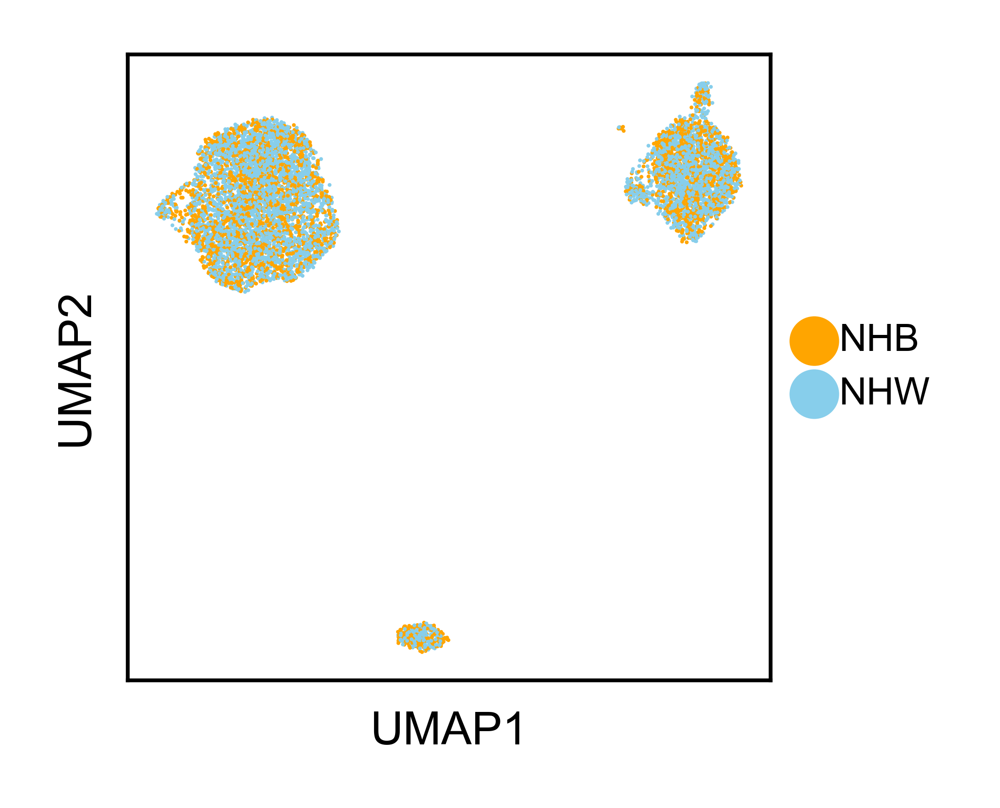

In [163]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race'
d.obs['race'] = [str(x).replace('1','NHB').replace('0','NHW') for x in d.obs['race']]


order = cells_group['Mono']
pal_ordered = [palette_all[c] for c in order]

sc.pl.umap(
    d,
    color=covar,
    palette=['orange','skyblue'],
    size=1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig('plots/F6_2/DC_race.svg')

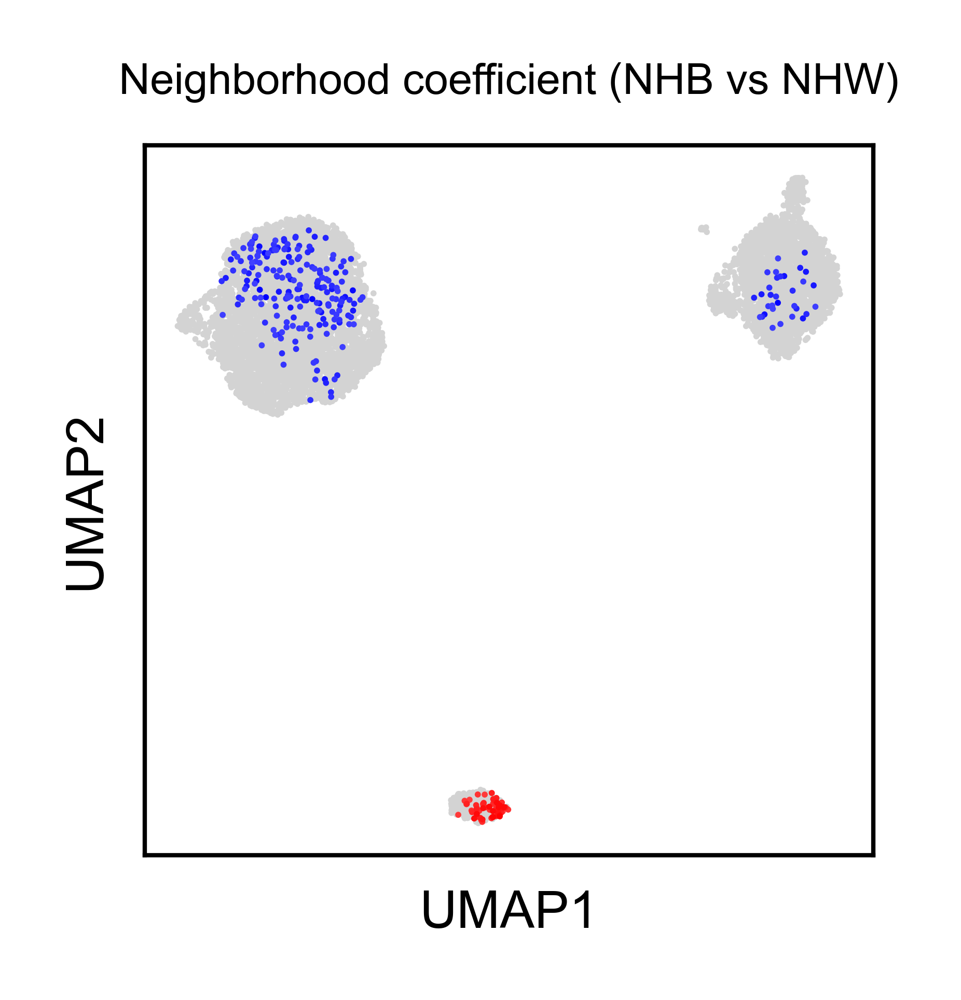

In [10]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race' 

coef_col = f"{covar}_coef"
fdr_col = f"{covar}_coef_fdr"
color_col = f"{covar}_coef_plot"

d.obs[color_col] = np.where(d.obs[fdr_col] < 0.1, d.obs[coef_col], np.nan)   # nan will show as gray in sc.pl.umap
sc.pl.umap(
    d,
    color=color_col,
    s=2,
    ax=ax,
    vmin=-1,
    vmax=1,
    cmap='seismic',
    na_color='lightgray',   # Gray for nan (non-significant)
    title='',
    colorbar_loc=None,
    show=False         # So you can further edit if needed
)

# cbar = ax.collections[0].colorbar
# ticks = [-1, -0.5, 0, 0.5, 1]
# cbar.set_ticks(ticks)
# cbar.set_ticklabels([str(t) for t in ticks])


ax.set_title('Neighborhood coefficient (NHB vs NHW)',fontsize=5)
plt.savefig('plots/F6_2/DC_NbCoeff.svg')

In [11]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]>0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

cDC1: 67 (100.00%)


In [12]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]<0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

cDC2: 198 (86.09%)
pDC: 32 (13.91%)


## Cell type + Disease state

In [10]:
cts = 0

for celltype in [
    'cDC1',
    'cDC2',
    'pDC'
]:
    for group in ['HRL','DCIS','BC']:

        for db in ['hallmark','immport']:

            cts += 1
            
            raw = pd.read_csv(
                f'data/Figure6/CNArankNHBvsW_{celltype}_{group}_{db}.csv', 
                index_col=0)
            
            # dfp = raw[raw['FDR q-val']<0.1].sort_values('NES', ascending=False)
            dfp = raw#[raw['NOM p-val']<0.05].sort_values('NES', ascending=False)

            dfp['Tag %'] = (
                dfp['Tag %']
                .astype(str)
                .apply(lambda x: eval(x) if '/' in x else float(x))
            )
            dfp['Tag %'] = dfp['Tag %'] * 100
            dfp['log_p'] = -np.log10(dfp['NOM p-val'].replace(0, 1e-300))
            
            # Sort by NES
            dfp = dfp.sort_values('NES', ascending=False)
            
            # filter - 
            # dfp = dfp[dfp['Tag %']>=30]
            dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]

            dfp['analysis_celltype'] = [celltype]*dfp.shape[0]
            dfp['analysis_group'] = [group]*dfp.shape[0]
            dfp['analysis_db'] = [db]*dfp.shape[0]

            out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_celltype,analysis_group,analysis_db
5,prerank,G2M CHECKPOINT,0.476262,1.422972,0.000000,0.149031,0.228,43.589744,20.04%,E2F3;RBL1;HUS1;HIF1A;SS18;SLC12A2;RACGAP1;YTHD...,300.000000,cDC1,HRL,hallmark
6,prerank,MITOTIC SPINDLE,0.472006,1.407351,0.003413,0.085079,0.257,44.723618,19.05%,NEDD9;MYO9B;NET1;WASL;RICTOR;PCM1;TBCD;FARP1;R...,2.466868,cDC1,HRL,hallmark
16,prerank,INTERFERON GAMMA RESPONSE,0.399473,1.191556,0.067358,0.511236,0.909,38.775510,18.11%,IDO1;AUTS2;IRF8;HLA-DQA1;CMTR1;HLA-DRB1;PELI1;...,1.171614,cDC1,HRL,hallmark
17,prerank,INTERFERON ALPHA RESPONSE,0.430141,1.185365,0.105647,0.407551,0.919,37.500000,14.49%,CMTR1;TRIM5;TRIM14;EIF2AK2;PNPT1;IFI44L;LGALS3...,0.976144,cDC1,HRL,hallmark
18,prerank,BILE ACID METABOLISM,0.421311,1.163565,0.123909,0.392848,0.951,25.961538,16.45%,NEDD4;SLC23A2;GNPAT;PEX26;ATXN1;SCP2;ACSL5;SLC...,0.906896,cDC1,HRL,hallmark
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5,prerank,ROS AND RNS PRODUCTION IN PHAGOCYTES,-0.652828,-1.340491,0.009091,0.313894,0.766,51.428571,23.07%,ATP6V0E1;RAC2;NCF4;ATP6V1B2;ATP6V0D1;ATP6V1H;A...,2.041393,pDC,BC,immport
4,prerank,NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR SIGN...,-0.691158,-1.343278,0.031250,0.376851,0.752,36.842105,5.80%,GPR108;CD300A;ARRB2;OTUD4;GPS2;YWHAE;RNF115,1.505150,pDC,BC,immport
3,prerank,TNFR2 NON-CANONICAL NF-KB PATHWAY,-0.623328,-1.347339,0.000000,0.470612,0.731,49.000000,18.73%,PSMB8;PSMC2;PSMD10;PSMB6;UBA3;PSMD9;PSMA5;PSMA...,300.000000,pDC,BC,immport
2,prerank,NEUTROPHIL DEGRANULATION,-0.609416,-1.356238,0.000000,0.623158,0.686,53.318584,24.84%,GRN;CTSC;NPC2;S100A11;HLA-B;PSAP;FTL;VAMP8;DYN...,300.000000,pDC,BC,immport


In [11]:
tmp = out[(out['analysis_db']=='immport') & (out['FDR q-val']<0.1)]

Counter(tmp['Term'])

Counter({'INNATE IMMUNE RESPONSE IN MUCOSA': 6,
         'ANTIMICROBIAL HUMORAL RESPONSE': 4,
         'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE': 3,
         'COSTIMULATION BY THE CD28 FAMILY': 2,
         'INTERFERON GAMMA SIGNALING': 2,
         'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY': 2,
         'INTERFERON ALPHA/BETA SIGNALING': 2,
         'TNFR2 NON-CANONICAL NF-KB PATHWAY': 2,
         'B CELL DIFFERENTIATION': 2,
         'BUTYROPHILIN (BTN) FAMILY INTERACTIONS': 1,
         'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE': 1,
         'T CELL COSTIMULATION': 1,
         'LYMPHOCYTE COSTIMULATION': 1,
         'ANTIGEN PROCESSING AND PRESENTATION': 1,
         'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY': 1,
         'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING': 1,
         'MHC CLASS II ANTIGEN PRESENTATION': 1,
         'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS': 1,
         'TOLL-LIKE RECEPTOR CASCADES'

In [12]:
list_sel = [
# 'INNATE IMMUNE RESPONSE IN MUCOSA',
'ANTIMICROBIAL HUMORAL RESPONSE',
'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
'COSTIMULATION BY THE CD28 FAMILY',
'INTERFERON GAMMA SIGNALING',
'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
'INTERFERON ALPHA/BETA SIGNALING',
'TNFR2 NON-CANONICAL NF-KB PATHWAY',
# 'B CELL DIFFERENTIATION',
'BUTYROPHILIN (BTN) FAMILY INTERACTIONS',
# 'T CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
# 'T CELL COSTIMULATION',
# 'LYMPHOCYTE COSTIMULATION',
'ANTIGEN PROCESSING AND PRESENTATION',
'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
'INTERLEUKIN-3, INTERLEUKIN-5 AND GM-CSF SIGNALING',
'MHC CLASS II ANTIGEN PRESENTATION',
'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
'TOLL-LIKE RECEPTOR CASCADES',
# 'T CELL MEDIATED CYTOTOXICITY',
'IMMUNE RESPONSE TO TUMOR CELL',
'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
'LEUKOCYTE MEDIATED CYTOTOXICITY',
'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
# 'ANTIMICROBIAL PEPTIDES',
# 'NEUTROPHIL DEGRANULATION',
'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
# 'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
# 'B CELL ACTIVATION',
# 'GROWTH HORMONE RECEPTOR SIGNALING',
'DIAPEDESIS',
'INTERLEUKIN-2 FAMILY SIGNALING',
'NEGATIVE REGULATION OF CYTOPLASMIC PATTERN RECOGNITION RECEPTOR SIGNALING PATHWAY',
'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
'RAP1 SIGNALLING',
'ACTIVATION OF INNATE IMMUNE RESPONSE',
'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
'LEUKOCYTE HOMEOSTASIS',
'ROS AND RNS PRODUCTION IN PHAGOCYTES',
'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY'    
]

/tmp/ipykernel_3959105/2353906028.py:53: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(3, 2.5))


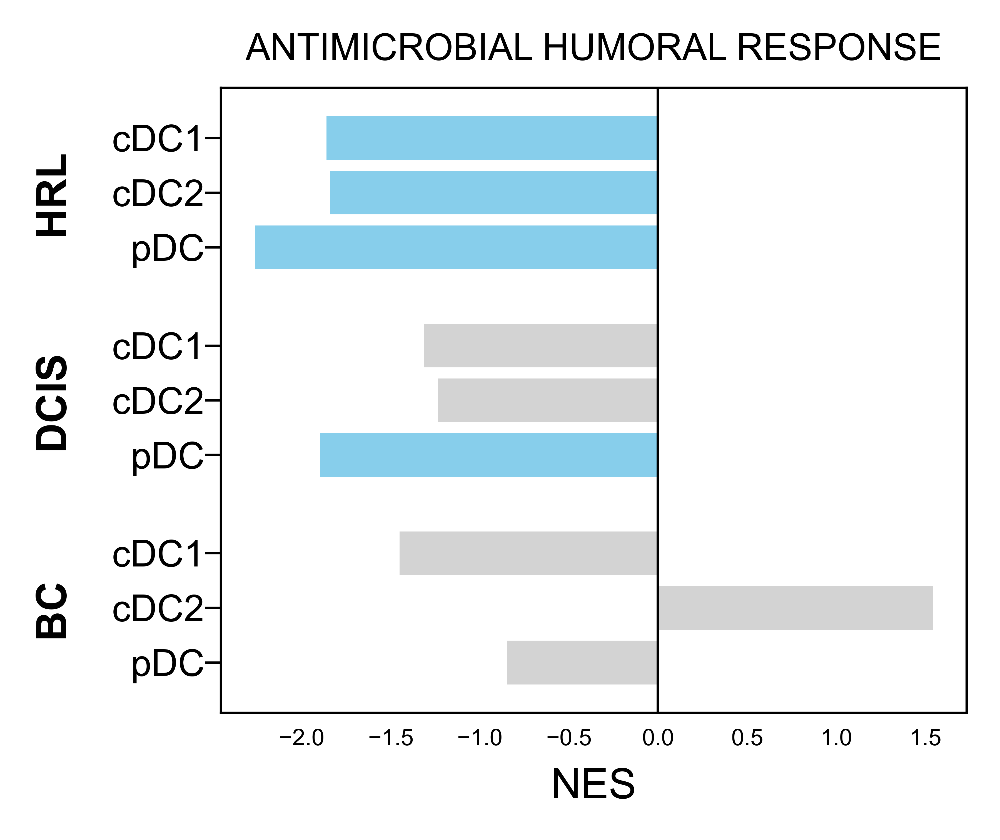

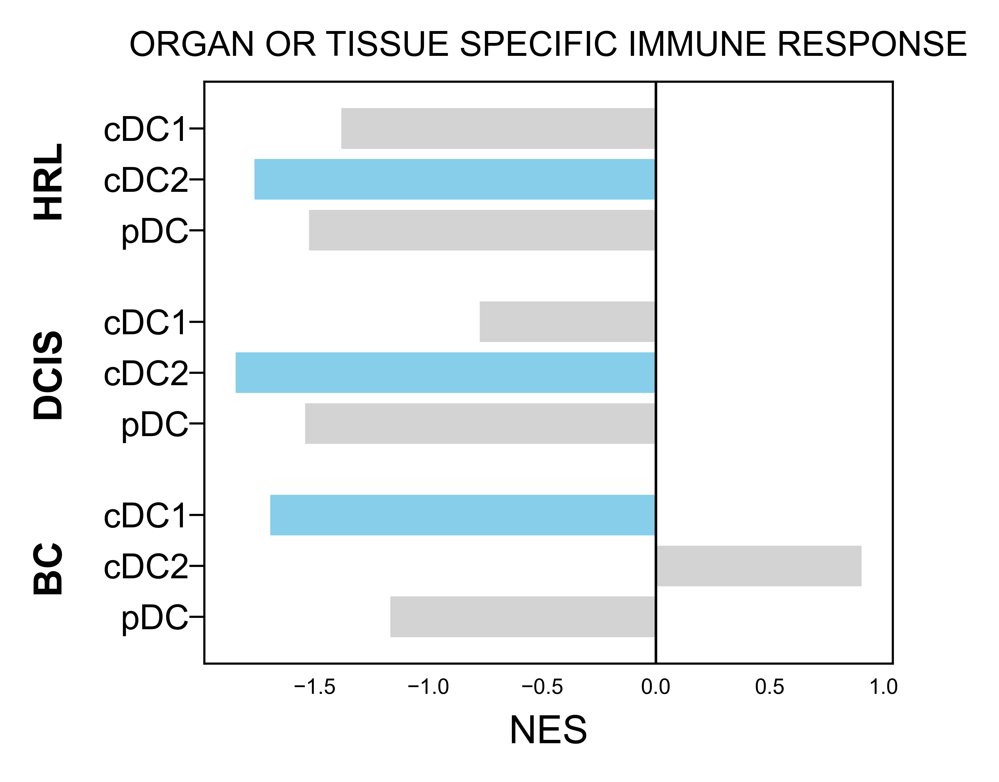

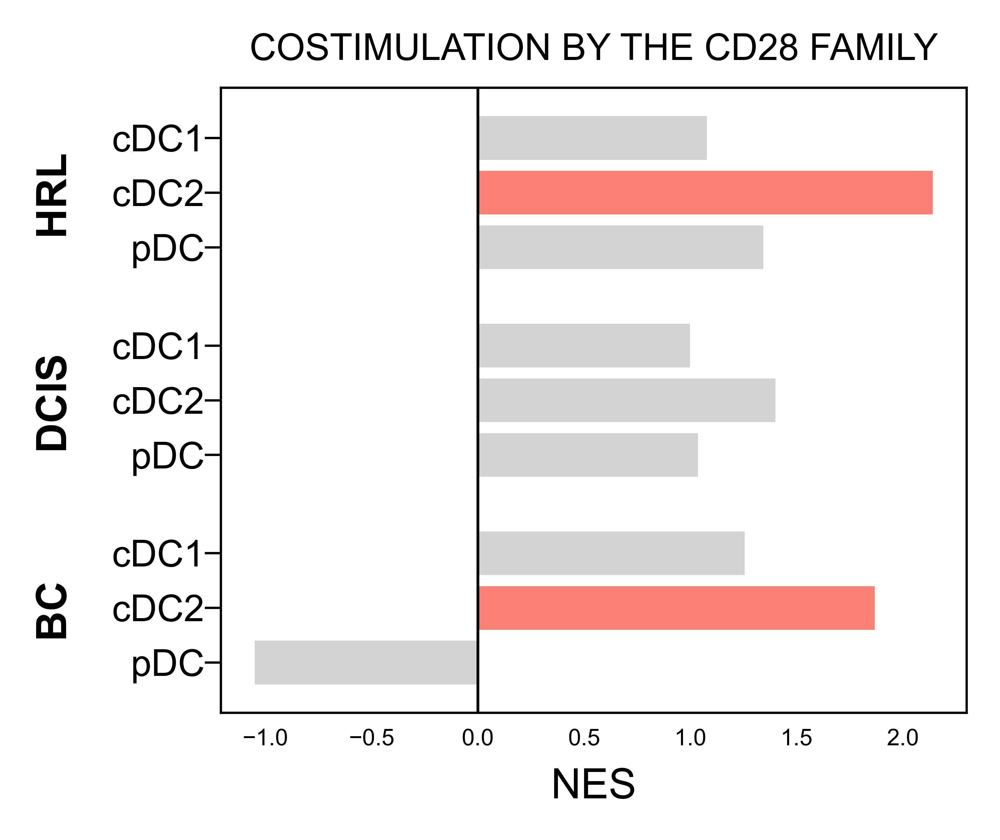

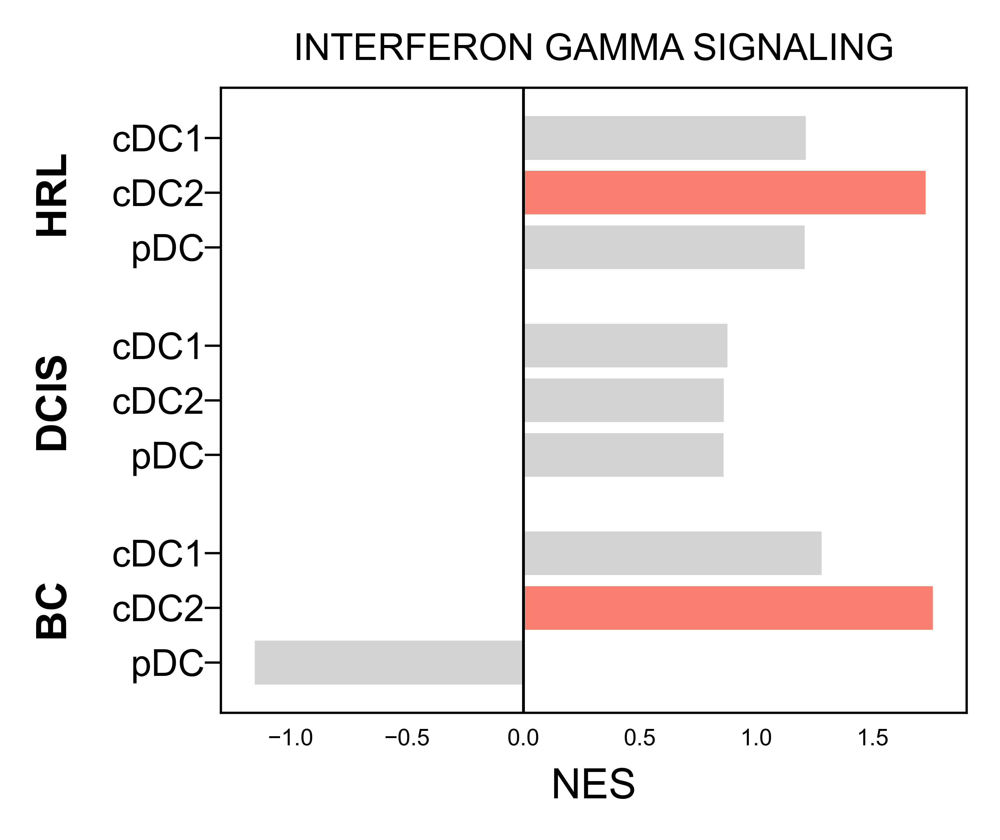

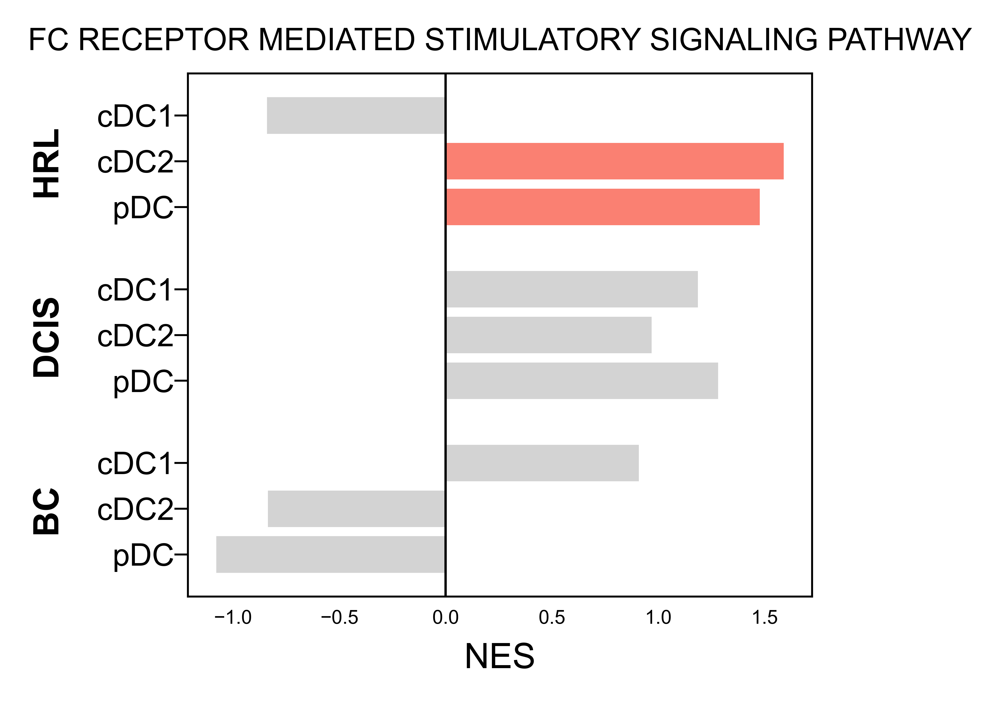

...

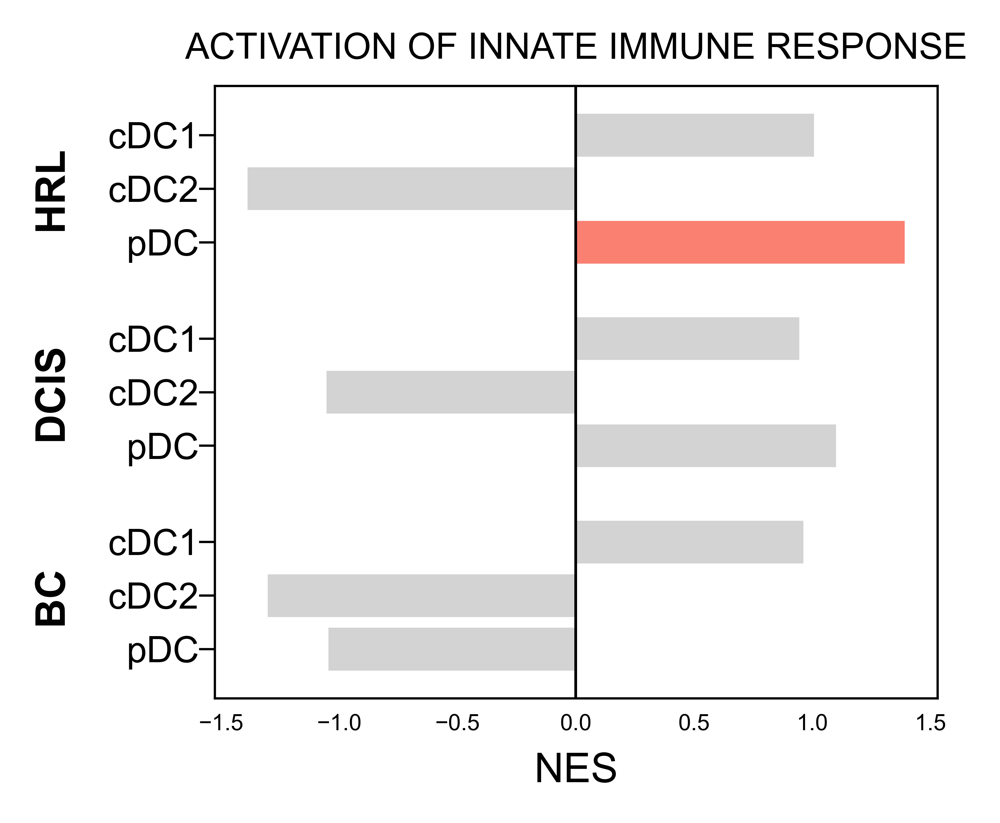

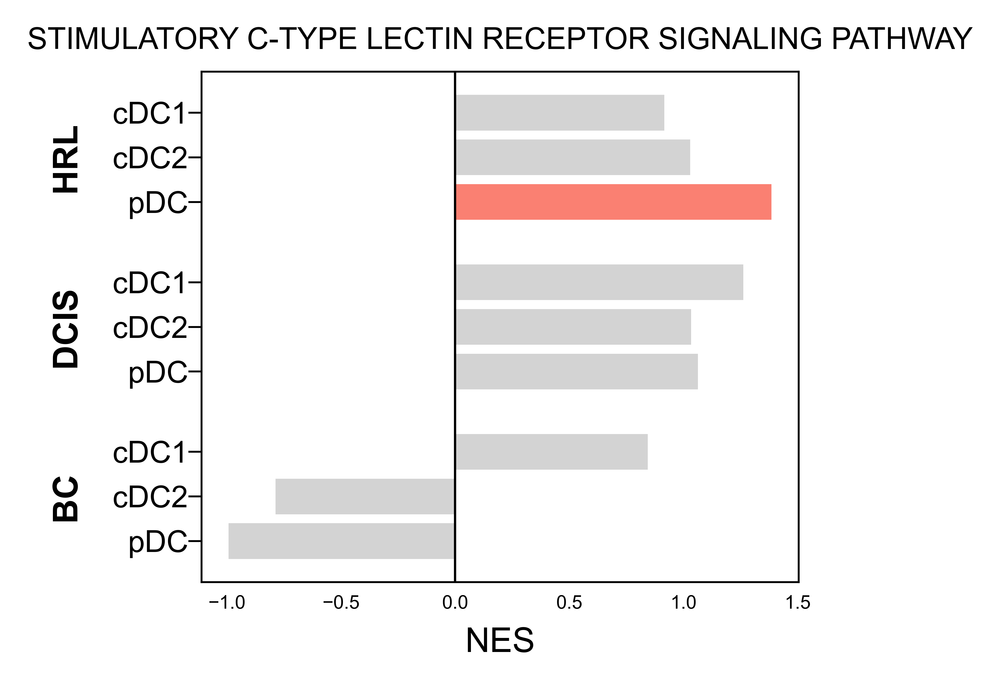

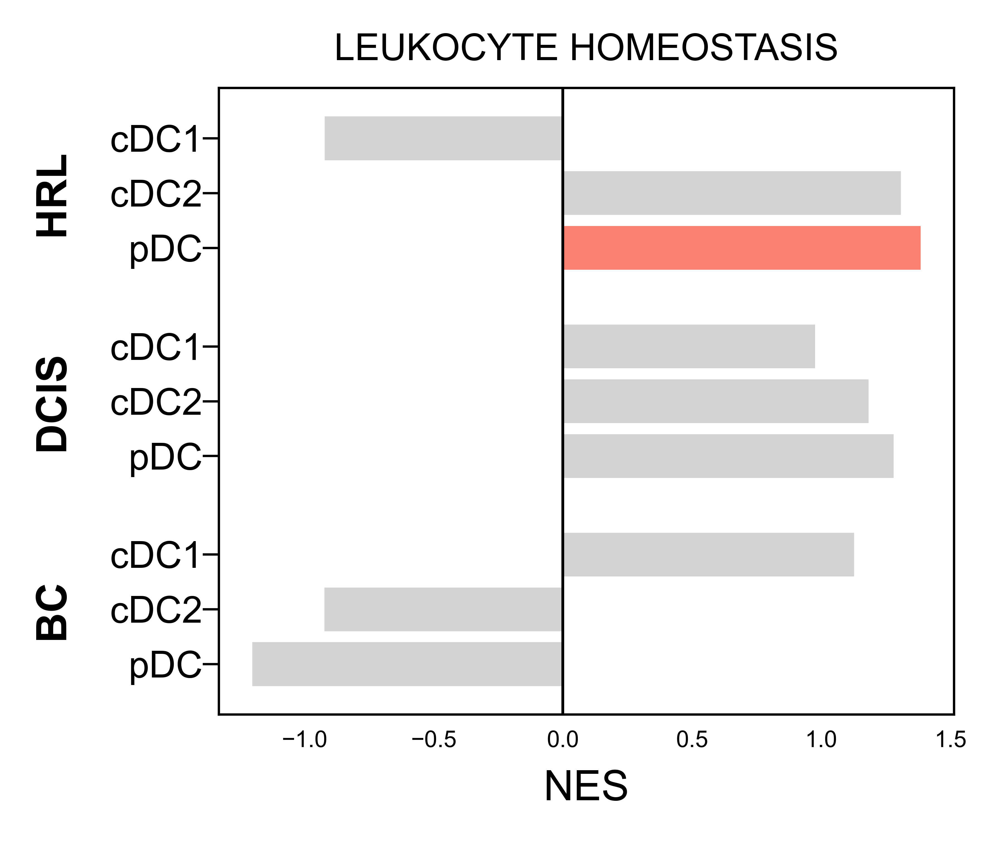

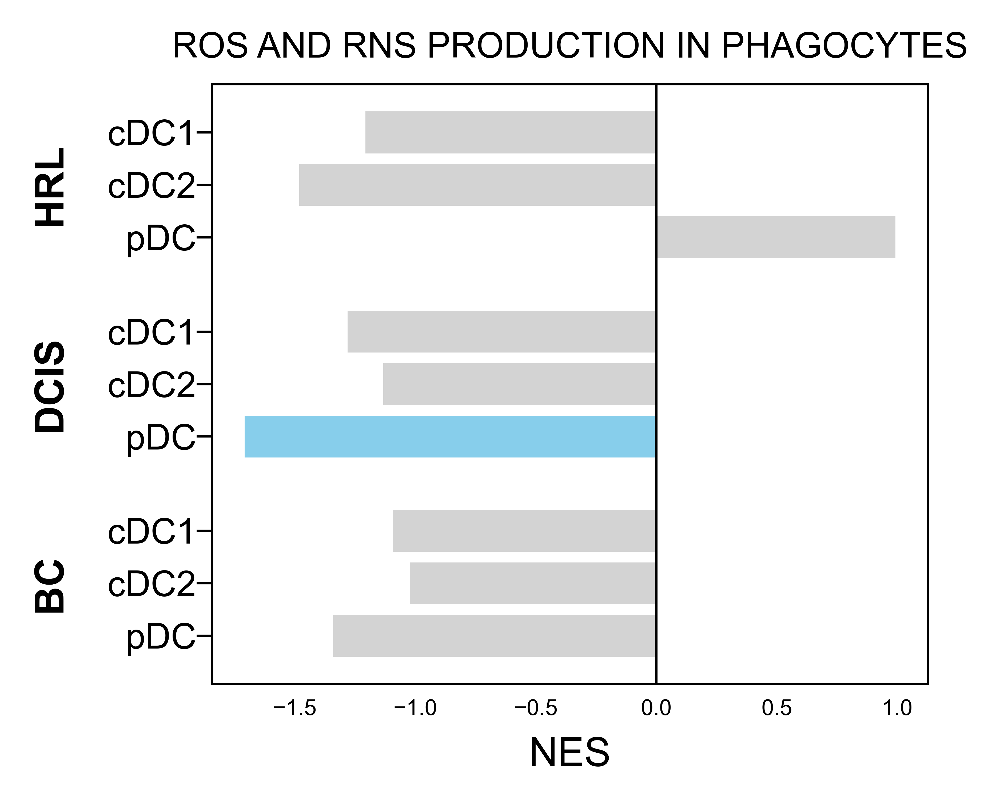

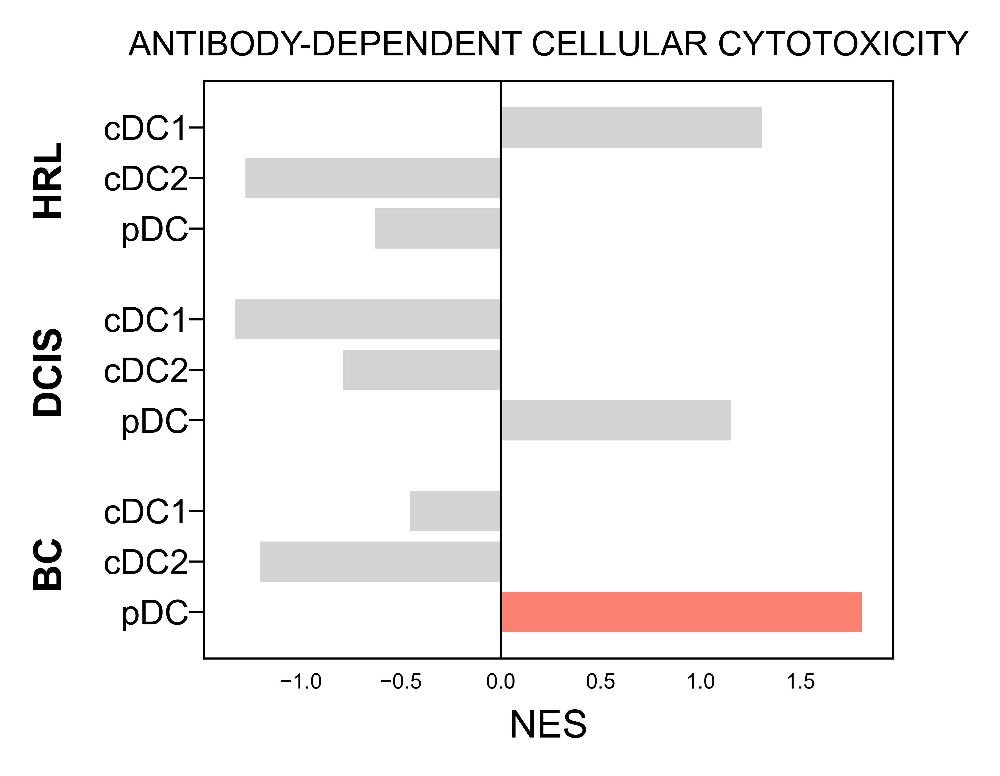

In [32]:
for path_sel in list_sel:
    
    dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
    qthres = .1
    
    abbr = {
        'cDC1': 'cDC1',
        'cDC2': 'cDC2',
        'pDC': 'pDC'
    }
    
    df = dfp.copy()
    df['ct'] = df['analysis_celltype'].map(abbr)
    
    group_order = df['analysis_group'].unique()
    ct_order = ['cDC1','cDC2','pDC']
    
    # ---- build plotting table ----
    rows = []
    y = 0
    gap = 0.8
    group_centers = {}
    
    for g in group_order:
        sub = df[df['analysis_group'] == g]
        start = y
        for ct in ct_order:
            r = sub[sub['ct'] == ct]
            if not r.empty:
                r = r.iloc[0]
                rows.append({
                    'y': y,
                    'NES': r['NES'],
                    'q': r['FDR q-val'],
                    'ct': ct,
                    'group': g
                })
                y += 1
        group_centers[g] = (start + y - 1) / 2
        y += gap
    
    plot_df = pd.DataFrame(rows)
    
    # ---- colors ----
    colors = [
        'salmon' if (q < qthres and nes > 0)
        else 'skyblue' if (q < qthres and nes < 0)
        else 'lightgray'
        for nes, q in zip(plot_df['NES'], plot_df['q'])
    ]
    
    # ---- plot ----
    fig, ax = plt.subplots(figsize=(3, 2.5))
    ax.barh(plot_df['y'], plot_df['NES'], color=colors)
    ax.axvline(0, color='black', lw=0.6)
    
    ax.set_title(path_sel, fontsize=8)
    ax.set_yticks(plot_df['y'])
    ax.set_yticklabels(plot_df['ct'], fontsize=8)
    
    # ---- group labels ----
    for g, yc in group_centers.items():
        ax.text(
            -0.2, yc, g,
            ha='right', va='center',
            fontsize=9, fontweight='bold',
            rotation=90,
            transform=ax.get_yaxis_transform()
        )
    
    ax.set_xlabel('NES', fontsize=9)
    ax.invert_yaxis()
    plt.tight_layout()
    
    # plt.savefig(f'plots/F6/Mono_{path_sel}.svg')

In [33]:
panel_title_map = {
    'INTERFERON ALPHA/BETA SIGNALING': 'Type I IFN Signaling',
    'INTERFERON GAMMA SIGNALING': 'IFN-γ Signaling',

    'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE': 'Leukocyte Migration',
    'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE': 'Leukocyte Activation',

    'TNFR2 NON-CANONICAL NF-KB PATHWAY': 'TNFR2 Non-Canonical NF-κB'
}

In [34]:
list(panel_title_map.keys())

['INTERFERON ALPHA/BETA SIGNALING',
 'INTERFERON GAMMA SIGNALING',
 'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
 'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
 'TNFR2 NON-CANONICAL NF-KB PATHWAY']

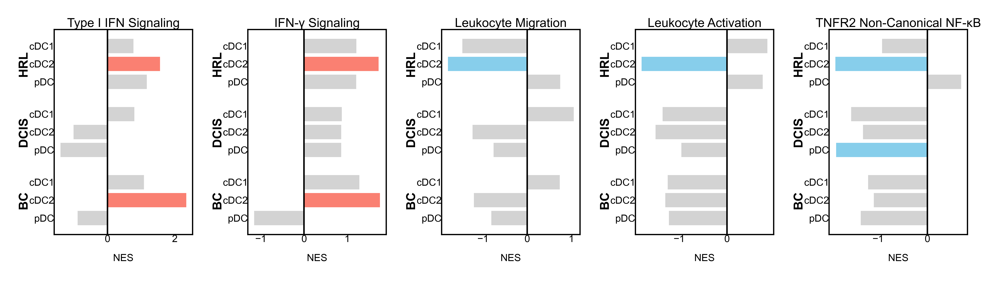

In [35]:
# make 1 row N columns
list_sel = list(panel_title_map.keys())

n = len(list_sel)
fig, axes = plt.subplots(
    1, n,
    figsize=(6.5, 1.5),   # scale width by number
    sharey=False
)

for ax, path_sel in zip(axes, list_sel):
    
    dfp = out[out['Term']==path_sel][['analysis_celltype','analysis_group','NES','FDR q-val']]
    qthres = .1
    
    abbr = {
        'cDC1': 'cDC1',
        'cDC2': 'cDC2',
        'pDC': 'pDC'
    }
    
    df = dfp.copy()
    df['ct'] = df['analysis_celltype'].map(abbr)
    
    group_order = df['analysis_group'].unique()
    ct_order = ['cDC1', 'cDC2', 'pDC']
    
    # ---- build plotting table ----
    rows = []
    y = 0
    gap = 0.8
    group_centers = {}
    
    for g in group_order:
        sub = df[df['analysis_group'] == g]
        start = y
        for ct in ct_order:
            r = sub[sub['ct'] == ct]
            if not r.empty:
                r = r.iloc[0]
                rows.append({
                    'y': y,
                    'NES': r['NES'],
                    'q': r['FDR q-val'],
                    'ct': ct,
                    'group': g
                })
                y += 1
        group_centers[g] = (start + y - 1) / 2
        y += gap
    
    plot_df = pd.DataFrame(rows)
    
    # ---- colors ----
    colors = [
        'salmon' if (q < qthres and nes > 0)
        else 'skyblue' if (q < qthres and nes < 0)
        else 'lightgray'
        for nes, q in zip(plot_df['NES'], plot_df['q'])
    ]
    
    # ---- plot ----
    ax.barh(plot_df['y'], plot_df['NES'], color=colors)
    ax.axvline(0, color='black', lw=0.6)

    panel_title = panel_title_map[path_sel]
    ax.set_title(panel_title, fontsize=5, pad=1)

    ax.set_xlabel('NES', fontsize=4)
    ax.set_yticks(plot_df['y'])
    ax.set_yticklabels(plot_df['ct'], fontsize=4)
    
    # tick cosmetics
    ax.tick_params(axis='x', length=.2, labelsize=4)
    ax.tick_params(axis='y', length=0)   # remove tick length
    
    # group labels
    for g, yc in group_centers.items():
        ax.text(
            -0.18, yc, g,
            ha='right', va='center',
            fontsize=5, fontweight='bold',
            rotation=90,
            transform=ax.get_yaxis_transform()
        )
    
    ax.invert_yaxis()


plt.subplots_adjust(wspace=0.4)
plt.savefig('plots/F6_2/DC_multiplot.svg')
plt.show()

## Disease state

In [33]:
cts = 0


for group in ['HRL','DCIS','BC']:

    for db in ['hallmark','immport']:

        cts += 1
        
        raw = pd.read_csv(
            f'data/Figure6/CNArankNHBvsW_DC_{group}_{db}.csv', 
            index_col=0)
        
        dfp = raw#[raw['FDR q-val']<0.05].sort_values('NES', ascending=False)

        dfp['Tag %'] = (
            dfp['Tag %']
            .astype(str)
            .apply(lambda x: eval(x) if '/' in x else float(x))
        )
        dfp['Tag %'] = dfp['Tag %'] * 100
        dfp['log_p'] = -np.log10(dfp['FDR q-val'].replace(0, 1e-300))
        
        # Sort by NES
        dfp = dfp.sort_values('NES', ascending=False)
        
        # filter - 
        # dfp = dfp[dfp['Tag %']>=30]
        dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]


        dfp['analysis_group'] = [group]*dfp.shape[0]
        dfp['analysis_db'] = [db]*dfp.shape[0]

        out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
4,prerank,PROTEIN SECRETION,0.610460,1.761376,0.000000,0.000532,0.001,49.473684,16.23%,DST;IGF2R;DOP1A;MON2;TPD52;SCRN1;ARFGEF1;TMX1;...,3.274129,HRL,hallmark
7,prerank,MITOTIC SPINDLE,0.524906,1.620063,0.000000,0.006383,0.023,48.241206,21.37%,CCDC88A;CD2AP;FLNB;DST;NET1;NEDD9;RICTOR;KIF20...,2.194948,HRL,hallmark
11,prerank,G2M CHECKPOINT,0.496483,1.522485,0.000000,0.022165,0.121,41.538462,19.01%,CCND1;KIF20B;PRIM2;SLC38A1;STAG1;STMN1;RBL1;MY...,1.654340,HRL,hallmark
14,prerank,INTERFERON ALPHA RESPONSE,0.501788,1.462545,0.006936,0.036705,0.242,40.625000,13.03%,MX1;IFI44L;TAP1;NCOA7;IRF7;SP110;CNP;ISG20;GMP...,1.435280,HRL,hallmark
16,prerank,ANDROGEN RESPONSE,0.487196,1.405269,0.017123,0.067451,0.465,31.250000,13.06%,CCND1;PLPP1;CDK6;UBE2J1;NGLY1;PMEPA1;SPCS3;TPD...,1.171010,HRL,hallmark
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8,prerank,ANTIMICROBIAL PEPTIDES,-0.634670,-1.460413,0.001058,0.112442,0.437,17.142857,3.56%,CCR2;RNASE6;S100A9;S100A8;TLR2;CD4,0.949073,BC,immport
7,prerank,INTERLEUKIN-20 FAMILY SIGNALING,-0.684893,-1.507340,0.006479,0.071081,0.261,68.181818,26.62%,JAK1;IFNLR1;TYK2;IL10RB;STAT2;STAT3;IFNL1;STAT...,1.148246,BC,immport
6,prerank,ROS AND RNS PRODUCTION IN PHAGOCYTES,-0.660576,-1.526455,0.002088,0.066250,0.192,54.285714,17.10%,ATP6V1B2;CYBB;HVCN1;NCF2;NCF4;ATP6V1A;ATP6V0D1...,1.178812,BC,immport
4,prerank,"COMPLEMENT ACTIVATION, LECTIN PATHWAY",-0.915026,-1.585208,0.002513,0.036346,0.073,16.666667,0.12%,FCN1,1.439547,BC,immport


In [34]:
DzState, db = 'HRL', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
       'IMMUNE RESPONSE TO TUMOR CELL', 'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
       'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
       'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       'NEGATIVE REGULATION OF HEMOPOIESIS',
       'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
       'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 'LEUKOCYTE CHEMOTAXIS',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
       'INTERLEUKIN-10 SIGNALING',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'INNATE IMMUNE RESPONSE IN MUCOSA', 'ANTIMICROBIAL PEPTIDES',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'ANTIMICROBIAL HUMORAL RESPONSE', 'NEUTROPHIL DEGRANULATION'],
      dtype=object)

In [35]:
paths_relevant = [
'NUCLEOTIDE-BINDING DOMAIN, LEUCINE RICH REPEAT CONTAINING RECEPTOR (NLR) SIGNALING PATHWAYS',
       'IMMUNE RESPONSE TO TUMOR CELL', 
    'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'ANTIBODY-DEPENDENT CELLULAR CYTOTOXICITY',
       'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
       'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       'NEGATIVE REGULATION OF HEMOPOIESIS',
       'INFLAMMATORY RESPONSE TO ANTIGENIC STIMULUS',
       # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 
       'LEUKOCYTE CHEMOTAXIS',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
       'INTERLEUKIN-10 SIGNALING',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA', 
    'ANTIMICROBIAL PEPTIDES',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'ANTIMICROBIAL HUMORAL RESPONSE'#,
    # 'NEUTROPHIL DEGRANULATION'    
]

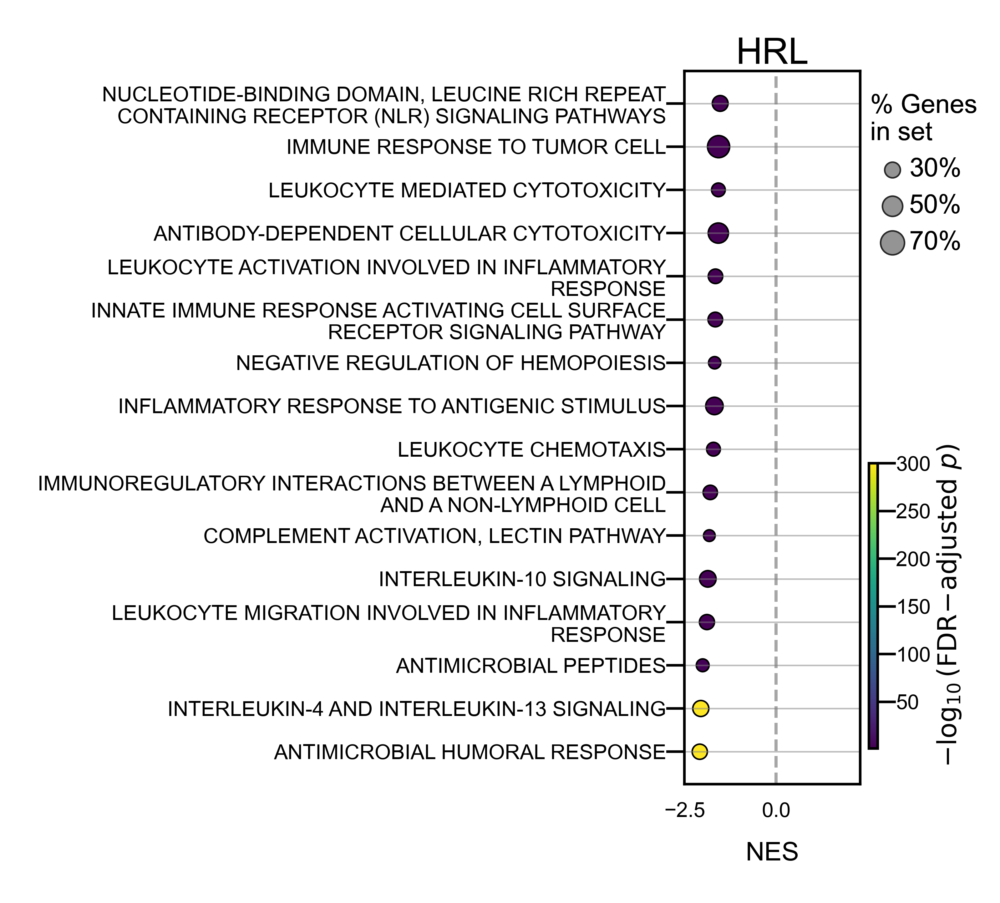

In [36]:
dfp2 = dfp[dfp['Term'].isin(paths_relevant)].reset_index(drop=True)

wrap_width = 50
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis


# Plot
fig, ax = plt.subplots(figsize=(.6
                                ,  2.5))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.1])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=4)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)
ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)
# plt.tight_layout()
plt.savefig(f"plots/S6_2/Bubble_DC_{DzState}_{db}.jpg", 
            dpi=600, 
            bbox_inches='tight'
            )

In [37]:
DzState, db = 'DCIS', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['COMPLEMENT CASCADE', 'INTERLEUKIN-12 FAMILY SIGNALING',
       'TYPE 2 IMMUNE RESPONSE',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'FC EPSILON RECEPTOR (FCERI) SIGNALING',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
       'ANTIGEN PROCESSING AND PRESENTATION', 'LEUKOCYTE CHEMOTAXIS',
       'C-TYPE LECTIN RECEPTORS (CLRS)',
       'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 'TCR SIGNALING',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       'INTERLEUKIN-1 FAMILY SIGNALING',
       'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
       'INTERLEUKIN-10 SIGNALING', 'ANTIMICROBIAL HUMORAL RESPONSE',
       'INNATE IMMUNE RESPONSE IN MUCOSA',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'ANTIMICROBIAL PEPTIDES', 'TNFR2 NON-CANONICAL NF-KB

In [38]:
paths_relevant = [
'COMPLEMENT CASCADE', 
    'INTERLEUKIN-12 FAMILY SIGNALING',
       'TYPE 2 IMMUNE RESPONSE',
       'INTERLEUKIN-4 AND INTERLEUKIN-13 SIGNALING',
       'FC EPSILON RECEPTOR (FCERI) SIGNALING',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       'LEUKOCYTE MEDIATED CYTOTOXICITY',
       'LEUKOCYTE ACTIVATION INVOLVED IN INFLAMMATORY RESPONSE',
       'ANTIGEN PROCESSING AND PRESENTATION', 
    'LEUKOCYTE CHEMOTAXIS',
       'C-TYPE LECTIN RECEPTORS (CLRS)',
    #    'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', 
    # 'TCR SIGNALING',
       'NEGATIVE REGULATION OF IMMUNE EFFECTOR PROCESS',
       'INTERLEUKIN-1 FAMILY SIGNALING',
       'COMPLEMENT ACTIVATION, ALTERNATIVE PATHWAY',
       'INTERLEUKIN-10 SIGNALING', 
    'ANTIMICROBIAL HUMORAL RESPONSE',
       # 'INNATE IMMUNE RESPONSE IN MUCOSA',
       'LEUKOCYTE MIGRATION INVOLVED IN INFLAMMATORY RESPONSE',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'ANTIMICROBIAL PEPTIDES', 
    'TNFR2 NON-CANONICAL NF-KB PATHWAY',
       # 'NEUTROPHIL DEGRANULATION' 
]

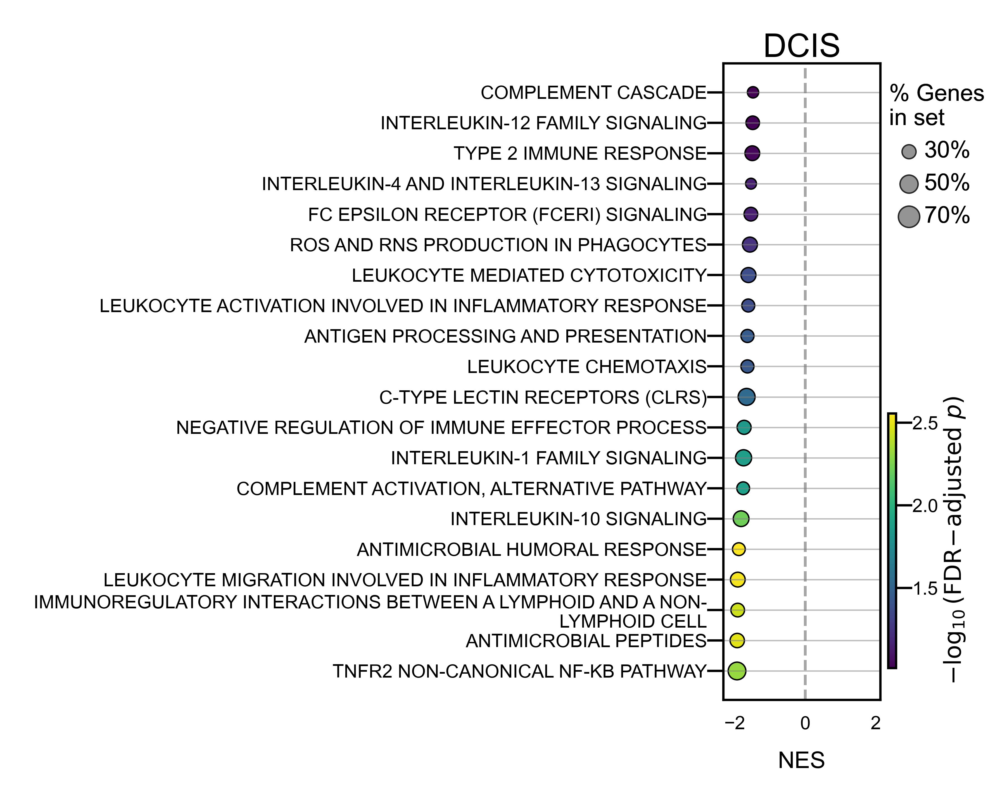

In [39]:
dfp2 = dfp[dfp['Term'].isin(paths_relevant)].reset_index(drop=True)

wrap_width = 60
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis


# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 2.5))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.1])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=4)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)
ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)
# plt.tight_layout()
plt.savefig(f"plots/S6_2/Bubble_DC_{DzState}_{db}.jpg", 
            dpi=600, 
            bbox_inches='tight'
            )

In [40]:
DzState, db = 'BC', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['INTERFERON ALPHA/BETA SIGNALING',
       'COSTIMULATION BY THE CD28 FAMILY',
       'INTERLEUKIN-20 FAMILY SIGNALING',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY', 'CELLULAR EXTRAVASATION'],
      dtype=object)

In [41]:
paths_relevant = [
    'INTERFERON ALPHA/BETA SIGNALING',
       'COSTIMULATION BY THE CD28 FAMILY',
       'INTERLEUKIN-20 FAMILY SIGNALING',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       'COMPLEMENT ACTIVATION, LECTIN PATHWAY',
    'CELLULAR EXTRAVASATION'
]

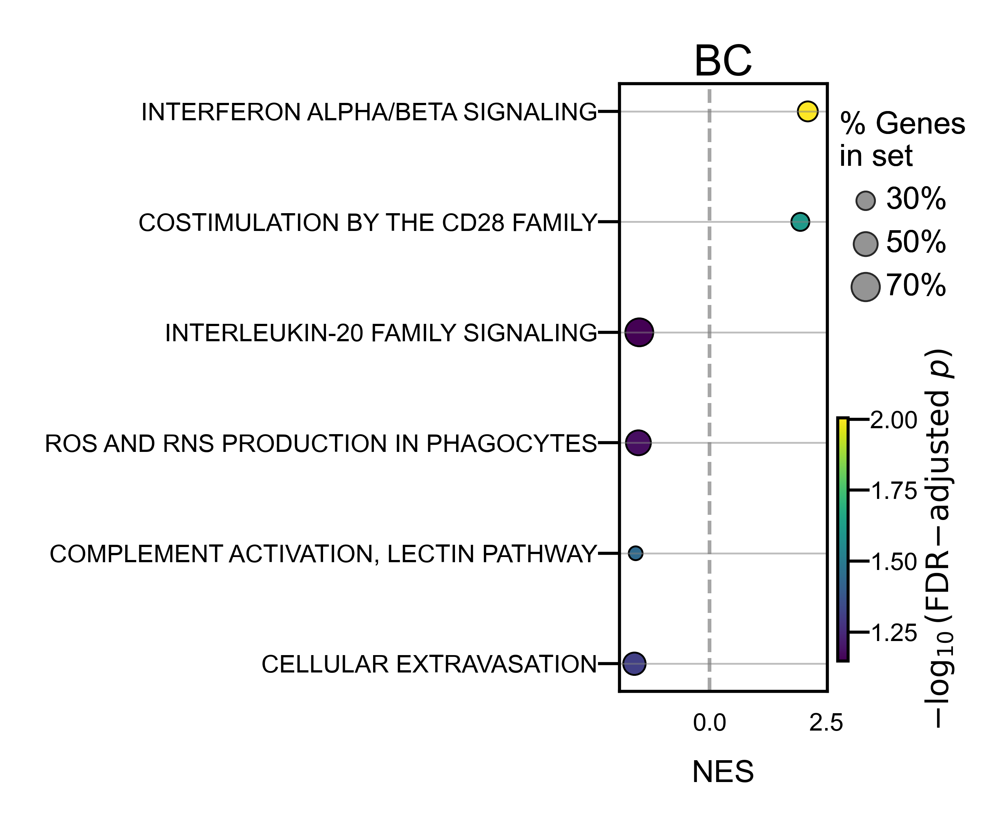

In [42]:
dfp2 = dfp[dfp['Term'].isin(paths_relevant)].reset_index(drop=True)

wrap_width = 60
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis


# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 1.8))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.2])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=4)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)
ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)
# plt.tight_layout()
plt.savefig(f"plots/S6_2/Bubble_DC_{DzState}_{db}.jpg", 
            dpi=600, 
            bbox_inches='tight'
            )